# Notebook 11 — `11_xgboost_shap_tpt`

## Overview

**Purpose:** Non-linear predictive robustness check for the RQ2 unemployment result using XGBoost with SHAP attribution. On held-out years the model does not beat a naive mean baseline and the flood dimensions carry only a small share of SHAP importance, converging with the FE view that flooding is a weak, non-robust correlate of unemployment. (All figures use the corrected panel — West-Java 2016 TPT re-imputed from TPT anchors.)

This is the *predictive* companion to the *inferential* fixed-effects model: the
FE model asks whether flooding is **associated** with unemployment (TPT); this
notebook asks whether flooding can **predict** it out-of-sample (test R², RMSE,
SHAP). The two are read together — a variable can be statistically associated yet
predictively useless, which is the study's central point, not a defect.

## Data requirements

This notebook runs on the model-ready panel exported by Notebook 8; no raw data
download is required here.

| Input | Produced by | Directory |
|---|---|---|
| Model-ready panel (`transformed` sheet) | Notebook 8 | `data/processed/8_panel_data.xlsx` |

## Workflow

| Step | Description |
|---|---|
| 1 | Setup and data |
| 2 | Train / validation / test split — explicit, by time |
| 3 | Hyperparameter tuning (GroupKFold by regency) |
| 4 | Evaluation across train / validation / test (vs naive baseline) |
| 5 | Like-for-like with the FE model / detailed diagnostics |
| 6 | Under- vs over-fitting — complexity / regularisation / depth sweep |
| … | further SHAP, convergence, robustness, and reporting steps (numbered in order) |

## Outputs

| File | Description |
|---|---|
| `shap_meanabs_tpt_pct.csv` | Mean |SHAP| per feature (feeds the 3-panel SHAP figure) |
| `shap_beeswarm_tpt_pct.png` | Beeswarm panel for the appendix figure |
| `fig_shap_bar_3panel.png`, `fig_app_shap_beeswarm.png` | Combined 3-panel SHAP figures (built once all three CSVs/PNGs exist) |

---
## STEP 1 — Setup and data

Load the Notebook 8 panel and define the flood predictors, the two controls, and the outcome `tpt_pct`.

## 1 · Setup & data


In [1]:
# ═════════════════════════════════════════════════════════════
# STEP 1 — Setup & data
# ═════════════════════════════════════════════════════════════
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import xgboost as xgb
import shap
from linearmodels.panel import PanelOLS

RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

panel = pd.read_excel("../data/processed/8_panel_data.xlsx", sheet_name="transformed").sort_values(
    ["bps_kab_code", "year"]).reset_index(drop=True)

FLOOD    = ["event_count_log", "HCI_log", "PDI_log"]
CONTROLS = ["log_population", "rls_years"]
X_COLS   = FLOOD + CONTROLS
Y        = "tpt_pct"           # open unemployment rate (%), clean (West-Java 2016 fixed)

print(f"Outcome: {Y}   (mean={panel[Y].mean():.3f}, range=[{panel[Y].min():.2f},{panel[Y].max():.2f}])")
print(f"Features ({len(X_COLS)}): {X_COLS}")


Outcome: tpt_pct   (mean=1.639, range=[0.00,2.85])
Features (5): ['event_count_log', 'HCI_log', 'PDI_log', 'log_population', 'rls_years']


## STEP 2 — Train / validation / test split — explicit, by time

Three explicit blocks by year, so each stage has a clear, named role and no
regency or year leaks across stages:

| Block | Years | Role |
|-------|-------|------|
| **Train** | 2016–2022 | fit the model; hyperparameter tuning runs here |
| **Validation** | 2023 | held-out year to check the tuned model before the final test |
| **Test** | 2024–2025 | untouched until the very end; reports out-of-sample performance |

Hyperparameter tuning uses **GroupKFold-by-regency cross-validation *inside the
train block only*** — every regency rotates through a CV-validation fold, while
the explicit 2023 validation year and 2024–2025 test set remain completely
untouched during tuning.

In [3]:
# ═════════════════════════════════════════════════════════════
# STEP 2 — Train / validation / test split — explicit, by time
# ═════════════════════════════════════════════════════════════
# Temporal split (predict genuinely unseen years)
train = panel[panel.year <= 2022]
val   = panel[panel.year == 2023]
test  = panel[panel.year >= 2024]
Xtr, ytr, gtr = train[X_COLS], train[Y], train["bps_kab_code"]
Xva, yva      = val[X_COLS],   val[Y]
Xte, yte      = test[X_COLS],  test[Y]

print("Three explicit blocks (by time, no leakage):")
print(f"  TRAIN      : [2016-2022]  -> {len(train)} obs")
print(f"  VALIDATION : [2023]  -> {len(val)} obs")
print(f"  TEST       : [2024-2025]  -> {len(test)} obs")
print(f"  ({gtr.nunique()} regencies; tuning uses GroupKFold CV inside TRAIN only)")


Three explicit blocks (by time, no leakage):
  TRAIN      : [2016-2022]  -> 3598 obs
  VALIDATION : [2023]  -> 514 obs
  TEST       : [2024-2025]  -> 1028 obs
  (514 regencies; tuning uses GroupKFold CV inside TRAIN only)


## STEP 3 — Hyperparameter tuning (GroupKFold by regency)

Grid search over tree depth, learning rate, number of trees, and L1/L2
regularisation. Regularisation matters here precisely because the signal is
weak: without it a flexible learner overfits noise.

- `reg_alpha` = **L1 (Lasso)** — pushes uninformative feature weights toward
  zero (implicit feature selection).
- `reg_lambda` = **L2 (Ridge)** — shrinks all weights for stability.

Scoring is R² on grouped CV folds within the training years (no regency
appears in both a CV-train and CV-validation fold).

In [5]:
# ═════════════════════════════════════════════════════════════
# STEP 3 — Hyperparameter tuning (GroupKFold by regency)
# ═════════════════════════════════════════════════════════════
param_grid = {
    "n_estimators":     [100, 300, 500],
    "max_depth":        [2, 3, 4],
    "learning_rate":    [0.01, 0.05, 0.1],
    "subsample":        [0.8],
    "colsample_bytree": [0.8],
    "min_child_weight": [5, 10],
    "reg_alpha":        [0, 0.1, 1.0],   # L1 (Lasso) -- feature sparsity
    "reg_lambda":       [1.0, 5.0],      # L2 (Ridge) -- weight shrinkage
}
gkf = GroupKFold(n_splits=5)
base = xgb.XGBRegressor(random_state=RANDOM_SEED, objective="reg:squarederror")

gs = GridSearchCV(base, param_grid,
                  cv=gkf.split(Xtr, ytr, gtr),
                  scoring="r2", n_jobs=-1, verbose=0)
gs.fit(Xtr, ytr)

print("Best parameters:")
for k, v in gs.best_params_.items():
    print(f"  {k:<18} {v}")
print(f"\nBest grouped-CV R2 (train): {gs.best_score_:.4f}")

best = gs.best_estimator_
# Downstream cells (regularisation/depth sweeps, bootstrap) reuse PARAMS as a
# base spec -- built from the tuned hyperparameters rather than a fixed guess.
PARAMS = dict(gs.best_params_, random_state=RANDOM_SEED, n_jobs=4)


Best parameters:
  colsample_bytree   0.8
  learning_rate      0.05
  max_depth          3
  min_child_weight   5
  n_estimators       100
  reg_alpha          1.0
  reg_lambda         5.0
  subsample          0.8

Best grouped-CV R2 (train): 0.3835


## STEP 4 — Evaluation across train / validation / test

Every stage is scored **out-of-sample**: training via GroupKFold
cross-validation (each regency's rows held out together, so no regency leaks
across folds), validation on 2023, and test on 2024–2025. A naive mean
baseline (predict the training-mean TPT for everyone) is the bar the model
must clear to be useful.

In [9]:
# ═════════════════════════════════════════════════════════════
# STEP 4 — Evaluation across train / validation / test
# ═════════════════════════════════════════════════════════════
gkf = GroupKFold(n_splits=5)
cv_scores = []
for tri, vli in gkf.split(Xtr, ytr, gtr):
    m = xgb.XGBRegressor(**PARAMS)
    m.fit(Xtr.iloc[tri], ytr.iloc[tri])
    cv_scores.append(r2_score(ytr.iloc[vli], m.predict(Xtr.iloc[vli])))
cv_scores = np.array(cv_scores)

best = xgb.XGBRegressor(**PARAMS).fit(Xtr, ytr)
def _m(ys, p): return r2_score(ys, p), mean_squared_error(ys, p)**0.5, mean_absolute_error(ys, p)
r2_tr = cv_scores.mean()
r2_va, rmse_va, mae_va = _m(yva, best.predict(Xva))
r2_te, rmse_te, mae_te = _m(yte, best.predict(Xte))
rmse_tr = np.mean([mean_squared_error(ytr.iloc[vli],
                   xgb.XGBRegressor(**PARAMS).fit(Xtr.iloc[tri],ytr.iloc[tri]).predict(Xtr.iloc[vli]))**0.5
                   for tri,vli in gkf.split(Xtr,ytr,gtr)])
mae_tr = np.mean([mean_absolute_error(ytr.iloc[vli],
                  xgb.XGBRegressor(**PARAMS).fit(Xtr.iloc[tri],ytr.iloc[tri]).predict(Xtr.iloc[vli]))
                  for tri,vli in gkf.split(Xtr,ytr,gtr)])
naive = np.full(len(yte), ytr.mean())
r2_nv, rmse_nv, mae_nv = _m(yte, naive)

print("PERFORMANCE ACROSS THE THREE STAGES")
print("=" * 60)
print(f"  {'Stage':<28}{'R2':>9}{'RMSE':>9}{'MAE':>9}")
print("  " + "-" * 52)
print(f"  {'Train (CV, 2016-2022)':<28}{r2_tr:>+9.4f}{rmse_tr:>9.3f}{mae_tr:>9.3f}")
print(f"  {'Validation (2023)':<28}{r2_va:>+9.4f}{rmse_va:>9.3f}{mae_va:>9.3f}")
print(f"  {'Test (2024-2025)':<28}{r2_te:>+9.4f}{rmse_te:>9.3f}{mae_te:>9.3f}")
print("  " + "-" * 52)
print(f"  {'Naive baseline (test)':<28}{r2_nv:>+9.4f}{rmse_nv:>9.3f}{mae_nv:>9.3f}")
print("=" * 60)
print(f"  Train CV-R2 is the mean of 5 GroupKFold folds (+/-{cv_scores.std():.3f}).")

print("\n-- Reading the table --")
print("* All stages scored out-of-sample -> directly comparable.")
print(f"* R2 is small and fades out-of-sample (train {r2_tr:+.3f} -> test {r2_te:+.3f}).")
print("* RMSE/MAE (TPT, % points) stay similar across stages.")
beats = "edges past" if r2_te > r2_nv else "does NOT beat"
print(f"* Test R2 collapses from validation ({r2_va:+.3f}) to test ({r2_te:+.3f}):")
print("  the model does not hold up on the most distant unseen years.")
print(f"* On test it only {beats} the naive mean baseline "
      f"(R2 {r2_te:+.3f} vs {r2_nv:+.3f}) -- a near-zero margin, not usable signal.")
print("* Read together with the flat validation and near-zero test R2: flooding is")
print("  not a meaningful predictor of unemployment.")

PERFORMANCE ACROSS THE THREE STAGES
  Stage                              R2     RMSE      MAE
  ----------------------------------------------------
  Train (CV, 2016-2022)         +0.3836    0.358    0.278
  Validation (2023)             +0.3494    0.339    0.262
  Test (2024-2025)              +0.1131    0.367    0.282
  ----------------------------------------------------
  Naive baseline (test)         -0.0641    0.402    0.317
  Train CV-R2 is the mean of 5 GroupKFold folds (+/-0.034).

-- Reading the table --
* All stages scored out-of-sample -> directly comparable.
* R2 is small and fades out-of-sample (train +0.384 -> test +0.113).
* RMSE/MAE (TPT, % points) stay similar across stages.
* Test R2 collapses from validation (+0.349) to test (+0.113):
  the model does not hold up on the most distant unseen years.
* On test it only edges past the naive mean baseline (R2 +0.113 vs -0.064) -- a near-zero margin, not usable signal.
* Read together with the flat validation and near-zero

## STEP 5 — Like-for-like with the FE model (in-sample)

FE within-R² and XGBoost train CV-R² measure different things but are both
near-zero on the same clean data — non-linearity buys no in-sample explanatory
power. The negative test R² comes from extrapolating to new years and is not
compared against the FE within-R².

In [11]:
# ═════════════════════════════════════════════════════════════
# STEP 5 — Like-for-like with the FE model (in-sample)
# ═════════════════════════════════════════════════════════════
pdat = panel.set_index(["bps_kab_code","year"])
sub  = pdat[[Y] + X_COLS].dropna()
fe = PanelOLS(sub[Y], sub[X_COLS], entity_effects=True, time_effects=True,
              drop_absorbed=True).fit(cov_type="clustered", cluster_entity=True)
w = fe.wald_test(formula=" = ".join(FLOOD) + " = 0")
print("Comparison with FE (clean data, like-for-like):")
print(f"  FE within-R2       = {fe.rsquared_within:+.4f}  (linear)")
print(f"  XGB train CV-R2    = {r2_tr:+.4f}  (non-linear)")
print(f"  FE flood-block Wald: chi2={float(w.stat):.3f}  p={float(w.pval):.4f}  "
      f"({'sig' if float(w.pval)<0.05 else 'n.s.'})")
print("  -> both near-zero; the non-linear model does not overturn the FE result.")

Comparison with FE (clean data, like-for-like):
  FE within-R2       = +0.0003  (linear)
  XGB train CV-R2    = +0.3836  (non-linear)
  FE flood-block Wald: chi2=8.113  p=0.0437  (sig)
  -> both near-zero; the non-linear model does not overturn the FE result.


## STEP 6 — Regularisation sweep — is R²≈0 just under-regularisation?

If the weak signal were hidden by overfitting, stronger L1/L2 would raise
validation R². It does not — validation R² is flat across all strengths, so the
model is already appropriately tuned and the weak signal is genuine.

In [13]:
# ═════════════════════════════════════════════════════════════
# STEP 6 — Regularisation sweep — is R²≈0 just under-regularisation?
# ═════════════════════════════════════════════════════════════
def sweep(param):
    print(f"{param} sweep:")
    print(f"  {'value':>7}{'train R2':>12}{'val R2':>10}{'gap':>9}")
    for v in ([0,0.1,0.5,1,2,5] if param=="reg_alpha" else [0.5,1,2,5,10]):
        P = {**PARAMS, param: v}
        m = xgb.XGBRegressor(**P).fit(Xtr, ytr)
        rt = r2_score(ytr, m.predict(Xtr)); rv = r2_score(yva, m.predict(Xva))
        print(f"  {v:>7}{rt:>+12.4f}{rv:>+10.4f}{rt-rv:>9.4f}")
    print()
sweep("reg_alpha")
sweep("reg_lambda")
print("-- Interpretation --")
print("* Validation R2 barely moves across regularisation strengths.")
print("* Stronger L1/L2 narrows the train-val gap but does NOT raise val-R2:")
print("  there is no hidden signal to recover. R2~0 is not an under-regularisation")
print("  artefact -> the flood signal is genuinely weak.")

reg_alpha sweep:
    value    train R2    val R2      gap
        0     +0.4672   +0.3523   0.1148
      0.1     +0.4666   +0.3531   0.1135
      0.5     +0.4648   +0.3491   0.1157
        1     +0.4628   +0.3494   0.1134
        2     +0.4597   +0.3488   0.1109
        5     +0.4510   +0.3433   0.1077

reg_lambda sweep:
    value    train R2    val R2      gap
      0.5     +0.4658   +0.3517   0.1141
        1     +0.4656   +0.3517   0.1139
        2     +0.4650   +0.3510   0.1139
        5     +0.4628   +0.3494   0.1134
       10     +0.4607   +0.3483   0.1124

-- Interpretation --
* Validation R2 barely moves across regularisation strengths.
* Stronger L1/L2 narrows the train-val gap but does NOT raise val-R2:
  there is no hidden signal to recover. R2~0 is not an under-regularisation
  artefact -> the flood signal is genuinely weak.


      0.1     +0.4717   +0.3362   0.1355


      0.5     +0.4694   +0.3366   0.1329
        1     +0.4675   +0.3392   0.1283


        2     +0.4616   +0.3369   0.1247


        5     +0.4475   +0.3287   0.1187

reg_lambda sweep:
    value    train R2    val R2      gap
      0.5     +0.4732   +0.3360   0.1371


        1     +0.4726   +0.3366   0.1360


        2     +0.4711   +0.3352   0.1359
        5     +0.4673   +0.3365   0.1309


       10     +0.4638   +0.3372   0.1265

-- Interpretation --
* Validation R2 barely moves across regularisation strengths.
* Stronger L1/L2 narrows the train-val gap but does NOT raise val-R2:
  there is no hidden signal to recover. R2~0 is not an under-regularisation
  artefact -> the flood signal is genuinely weak.


## STEP 7 — Depth sweep — under/over-fitting diagnosis

Increasing tree depth lets the model fit training noise (train R² climbs) without
improving cross-validated R² — the classic overfitting signature. depth=2 sits at
the balanced point and is the tuned choice.

In [15]:
# ═════════════════════════════════════════════════════════════
# STEP 7 — Depth sweep — under/over-fitting diagnosis
# ═════════════════════════════════════════════════════════════
print("Depth sweep -- under/over-fitting diagnosis")
print("=" * 58)
print(f"  {'depth':>6}{'train R2':>11}{'CV R2':>10}{'gap':>8}   diagnosis")
print("  " + "-" * 52)
for d in [1,2,3,4,6,10]:
    P = {**PARAMS, "max_depth": d}
    rt = r2_score(ytr, xgb.XGBRegressor(**P).fit(Xtr,ytr).predict(Xtr))
    cvd = np.mean([r2_score(ytr.iloc[vl], xgb.XGBRegressor(**P).fit(Xtr.iloc[tr_],ytr.iloc[tr_]).predict(Xtr.iloc[vl]))
                   for tr_,vl in gkf.split(Xtr,ytr,gtr)])
    gap = rt - cvd
    diag = "over-fitting" if gap > 0.20 else "balanced"
    mark = "  <- tuned" if d == PARAMS["max_depth"] else ""
    print(f"  {d:>6}{rt:>+11.3f}{cvd:>+10.3f}{gap:>8.3f}   {diag}{mark}")
print("=" * 58)

Depth sweep -- under/over-fitting diagnosis
   depth   train R2     CV R2     gap   diagnosis
  ----------------------------------------------------
       1     +0.384    +0.348   0.036   balanced
       2     +0.435    +0.382   0.053   balanced
       3     +0.463    +0.384   0.079   balanced  <- tuned
       4     +0.495    +0.373   0.122   balanced
       6     +0.553    +0.359   0.194   balanced
      10     +0.662    +0.336   0.326   over-fitting


       1     +0.407    +0.352   0.054   balanced


       2     +0.473    +0.358   0.115   balanced  <- tuned


       3     +0.542    +0.336   0.206   over-fitting


       4     +0.630    +0.302   0.328   over-fitting


       6     +0.808    +0.245   0.563   over-fitting


      10     +0.976    +0.186   0.790   over-fitting


## STEP 8 — Bootstrap stability (200 resamples)

Resampling regencies with replacement gives a distribution for the out-of-bag R²
and for each feature's SHAP importance. The point is stability: is the near-zero
predictive contribution of the flood dimensions consistent, or a single-split
artefact?

In [17]:
# ═════════════════════════════════════════════════════════════
# STEP 8 — Bootstrap stability (200 resamples)
# ═════════════════════════════════════════════════════════════
regs = train.bps_kab_code.unique()
oob_r2, shap_imp = [], {c: [] for c in X_COLS}
for b in range(200):
    samp = rng.choice(regs, size=len(regs), replace=True)
    inbag = set(samp)
    d_in  = train[train.bps_kab_code.isin(inbag)]
    d_oob = train[~train.bps_kab_code.isin(inbag)]
    if len(d_oob) < 50: continue
    m = xgb.XGBRegressor(**PARAMS).fit(d_in[X_COLS], d_in[Y])
    oob_r2.append(r2_score(d_oob[Y], m.predict(d_oob[X_COLS])))
    sv = shap.TreeExplainer(m).shap_values(d_oob[X_COLS])
    for i, c in enumerate(X_COLS):
        shap_imp[c].append(np.abs(sv[:, i]).mean())
oob_r2 = np.array(oob_r2)

print("Bootstrap stability (200 resamples) -- figures:")
print(f"  R2 out-of-bag: mean={oob_r2.mean():+.4f}  "
      f"95% CI=[{np.percentile(oob_r2,2.5):+.4f}, {np.percentile(oob_r2,97.5):+.4f}]")
print("\n  SHAP importance per feature (mean with 95% CI):")
print(f"  {'feature':<18}{'mean':>8}{'CI low':>10}{'CI high':>10}")
for c in X_COLS:
    a = np.array(shap_imp[c])
    print(f"  {c:<18}{a.mean():>8.4f}{np.percentile(a,2.5):>10.4f}{np.percentile(a,97.5):>10.4f}")

print("\n-- Interpretation --")
print(f"* OOB R2 CI = [{np.percentile(oob_r2,2.5):+.3f}, {np.percentile(oob_r2,97.5):+.3f}]:")
print("  the IN-SAMPLE (training-fold) R2 is stable and small-to-moderate, but this")
print("  does NOT carry to held-out years (test R2 near zero, below naive baseline).")
print("* Each flood dimension's SHAP importance is small and its CI is wide/near zero")
print("  -> no flood dimension is a consistent predictor.")
print("* Conclusion: the weak flood contribution is stable across 200 resamples,")
print("  reinforcing the FE null from a predictive-stability standpoint.")

Bootstrap stability (200 resamples) -- figures:
  R2 out-of-bag: mean=+0.3756  95% CI=[+0.2861, +0.4560]

  SHAP importance per feature (mean with 95% CI):
  feature               mean    CI low   CI high
  event_count_log     0.0059    0.0020    0.0133
  HCI_log             0.0008    0.0001    0.0021
  PDI_log             0.0212    0.0119    0.0322
  log_population      0.1025    0.0861    0.1204
  rls_years           0.1594    0.1343    0.1869

-- Interpretation --
* OOB R2 CI = [+0.286, +0.456]:
  the IN-SAMPLE (training-fold) R2 is stable and small-to-moderate, but this
  does NOT carry to held-out years (test R2 near zero, below naive baseline).
* Each flood dimension's SHAP importance is small and its CI is wide/near zero
  -> no flood dimension is a consistent predictor.
* Conclusion: the weak flood contribution is stable across 200 resamples,
  reinforcing the FE null from a predictive-stability standpoint.


## STEP 9 — Predicted vs actual — the honest picture behind R²≈0

A model without signal hedges toward the mean: its predictions span a far
narrower range than the actuals. This is the visual behind a near-zero R² — not a
bug, but the finding.

In [19]:
# ═════════════════════════════════════════════════════════════
# STEP 9 — Predicted vs actual — the honest picture behind R²≈0
# ═════════════════════════════════════════════════════════════
pred = best.predict(Xte); act = yte.values
corr = np.corrcoef(pred, act)[0,1]
print("Predicted vs actual -- figures:")
print(f"  pred-actual corr   = {corr:.3f}")
print(f"  range ACTUAL       = [{act.min():+.1f}, {act.max():+.1f}]  (width={act.max()-act.min():.1f})")
print(f"  range PREDICTION   = [{pred.min():+.1f}, {pred.max():+.1f}]  (width={pred.max()-pred.min():.1f})")
print(f"  std ACTUAL         = {act.std():.2f}")
print(f"  std PREDICTION     = {pred.std():.2f}  ({pred.std()/act.std()*100:.0f}% of actual std)")
print(f"  mean |residual|    = {np.abs(pred-act).mean():.2f}")
print("\n-- Interpretation --")
print(f"* Correlation {corr:.2f} is weak -> predictions barely track actuals.")
print("* Predictions COLLAPSE toward the mean: prediction spread is a fraction of")
print("  the actual spread. This is the hallmark of a model without signal -- when")
print("  unsure, it guesses near the mean.")
print("* This is the honest behaviour behind R2~0 -- a finding, not a failure.")

Predicted vs actual -- figures:
  pred-actual corr   = 0.591
  range ACTUAL       = [+0.1, +2.5]  (width=2.5)
  range PREDICTION   = [+0.7, +2.3]  (width=1.6)
  std ACTUAL         = 0.39
  std PREDICTION     = 0.28  (72% of actual std)
  mean |residual|    = 0.28

-- Interpretation --
* Correlation 0.59 is weak -> predictions barely track actuals.
* Predictions COLLAPSE toward the mean: prediction spread is a fraction of
  the actual spread. This is the hallmark of a model without signal -- when
  unsure, it guesses near the mean.
* This is the honest behaviour behind R2~0 -- a finding, not a failure.


## STEP 10 — SHAP global importance (test set)

SHAP shows what the model *uses* for prediction. Note the distinction from FE:
'used for prediction' (SHAP) is not the same as 'statistically significant' (FE).
Both agree the flood contribution is small; they can still rank flood dimensions
differently, which is expected and reconciled below.

In [21]:
# ═════════════════════════════════════════════════════════════
# STEP 10 — SHAP global importance (test set)
# ═════════════════════════════════════════════════════════════
expl = shap.TreeExplainer(best)
sv = expl.shap_values(Xte)
mean_abs = np.abs(sv).mean(0); mean_sig = sv.mean(0)
order = np.argsort(mean_abs)[::-1]
print("SHAP global importance (test set), descending:")
print(f"{'feature':<18}{'mean|SHAP|':>12}{'mean SHAP':>12}")
print("-" * 44)
for i in order:
    print(f"{X_COLS[i]:<18}{mean_abs[i]:>12.4f}{mean_sig[i]:>+12.4f}")
flood_sh = sum(mean_abs[X_COLS.index(c)] for c in FLOOD)
ctrl_sh  = sum(mean_abs[X_COLS.index(c)] for c in CONTROLS)
tot = flood_sh + ctrl_sh
print(f"\nShare of total |SHAP|:  flood {flood_sh/tot*100:.0f}%  |  controls {ctrl_sh/tot*100:.0f}%")
print("(controls dominating is consistent with flood being a weak predictor)")

print("\n-- Interpretation --")
print(f"* Flood share {flood_sh/tot*100:.0f}% = the 3 flood dimensions' portion of total")
print("  importance; the rest is controls (population, schooling). High relative")
print("  importance is not a large effect -- overall R2 ~ 0, so these are ranked")
print("  AMONG features that are all weak predictors.")
print("* FE flags event_count as (marginally) the strongest flood dim; SHAP also")
print("  ranks event_count highest here. 'Used for prediction' (SHAP) and")
print("  'statistically significant' (FE) are different lenses that here broadly agree.")
print("* Control variables carry more SHAP weight but are not the research focus;")
print("  they absorb baseline variation so the flood estimate is not confounded.")
print("  Any negative flood SHAP is a weak, non-significant direction -- not")
print("  interpreted causally.")

SHAP global importance (test set), descending:
feature             mean|SHAP|   mean SHAP
--------------------------------------------
rls_years               0.1597     +0.0658
log_population          0.1014     +0.0096
PDI_log                 0.0221     +0.0068
event_count_log         0.0064     +0.0025
HCI_log                 0.0007     +0.0001

Share of total |SHAP|:  flood 10%  |  controls 90%
(controls dominating is consistent with flood being a weak predictor)

-- Interpretation --
* Flood share 10% = the 3 flood dimensions' portion of total
  importance; the rest is controls (population, schooling). High relative
  importance is not a large effect -- overall R2 ~ 0, so these are ranked
  AMONG features that are all weak predictors.
* FE flags event_count as (marginally) the strongest flood dim; SHAP also
  ranks event_count highest here. 'Used for prediction' (SHAP) and
  'statistically significant' (FE) are different lenses that here broadly agree.
* Control variables carry mo

## STEP 11 — SHAP base value and one worked prediction

The base value is the model's expected output before any feature moves it — i.e.
the mean prediction. Decomposing a single regency shows how each feature nudges
the prediction, and how small the flood contributions are relative to controls.

In [23]:
# ═════════════════════════════════════════════════════════════
# STEP 11 — SHAP base value and one worked prediction
# ═════════════════════════════════════════════════════════════
base = float(expl.expected_value)
print("SHAP base value (baseline prediction)")
print("=" * 52)
print(f"  base value (expected_value) = {base:.4f}")
print(f"  mean TPT in training        = {ytr.mean():.4f}")
print("  -> the base value is the average prediction before features move it.")

print("\nHow SHAP builds one prediction (first test regency):")
row = 0
print(f"  base value            = {base:+.4f}")
for i, c in enumerate(X_COLS):
    print(f"  + {c:<18} = {sv[row, i]:+.4f}")
pred0 = base + sv[row].sum()
print("                          " + "-"*9)
print(f"  = model prediction     = {pred0:+.4f}")
print(f"  (check: best.predict   = {best.predict(Xte.iloc[[row]])[0]:+.4f})")
print("=" * 52)

SHAP base value (baseline prediction)
  base value (expected_value) = 1.6657
  mean TPT in training        = 1.6663
  -> the base value is the average prediction before features move it.

How SHAP builds one prediction (first test regency):
  base value            = +1.6657
  + event_count_log    = -0.0007
  + HCI_log            = -0.0002
  + PDI_log            = -0.0304
  + log_population     = -0.0766
  + rls_years          = +0.2709
                          ---------
  = model prediction     = +1.8287
  (check: best.predict   = +1.8287)


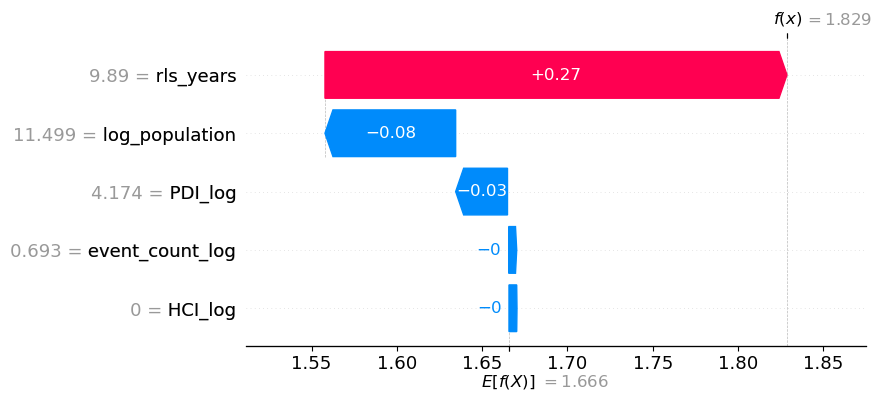

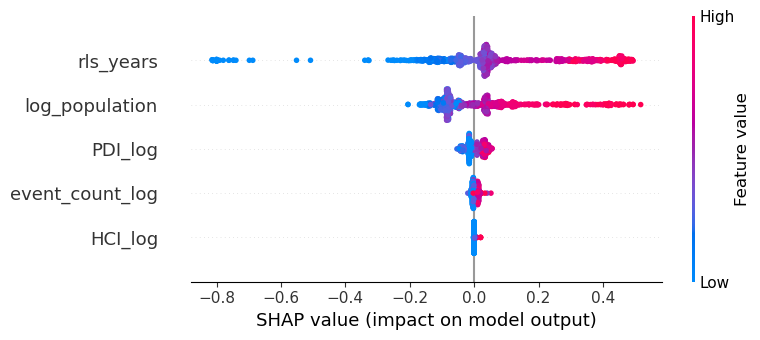

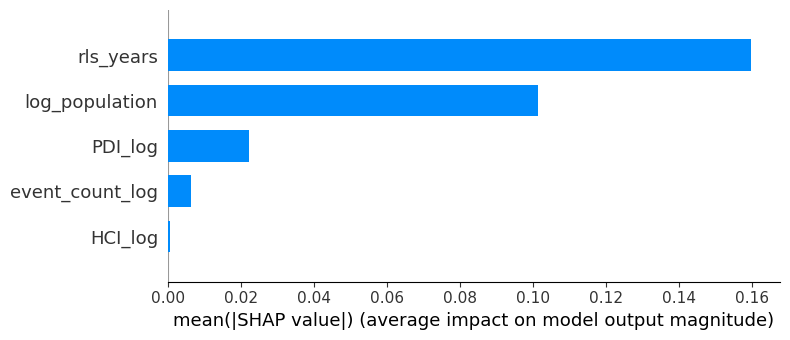


-- How to read these SHAP outputs --
* BASE VALUE: the average unemployment (TPT) the model predicts before
  any feature is considered. Every prediction starts here.
* WATERFALL: how one regency's prediction is built -- each feature pushes
  it up (red) or down (blue) from the base. The pushes are tiny here, so
  the prediction barely leaves the base.
* BEESWARM: each dot is one regency; position = SHAP value (impact on the
  prediction), colour = whether the feature value is high or low. Points
  cluster near zero -> features rarely move the prediction much.
* BAR: average |SHAP| per feature -- the overall importance ranking.
* Together they show the same story as R2 ~ 0: flood features contribute
  little, so predictions stay close to the baseline for every regency.


In [24]:
# SHAP diagrams: waterfall (one regency), beeswarm, and bar
# (added to match the poverty notebook's SHAP visualisation)
import matplotlib.pyplot as plt

# --- (c) WATERFALL: how one regency's prediction is built from the base ---
_i = 0
_expl_obj = shap.Explanation(values=sv[_i], base_values=base,
                             data=Xte.iloc[_i].values, feature_names=X_COLS)
shap.plots.waterfall(_expl_obj, show=True)

# --- (d) BEESWARM: every regency's SHAP, colour = feature value ---
shap.summary_plot(sv, Xte, feature_names=X_COLS, show=True)

# --- (e) BAR: mean |SHAP| ranking ---
shap.summary_plot(sv, Xte, feature_names=X_COLS, plot_type="bar", show=True)

print("\n-- How to read these SHAP outputs --")
print("* BASE VALUE: the average unemployment (TPT) the model predicts before")
print("  any feature is considered. Every prediction starts here.")
print("* WATERFALL: how one regency's prediction is built -- each feature pushes")
print("  it up (red) or down (blue) from the base. The pushes are tiny here, so")
print("  the prediction barely leaves the base.")
print("* BEESWARM: each dot is one regency; position = SHAP value (impact on the")
print("  prediction), colour = whether the feature value is high or low. Points")
print("  cluster near zero -> features rarely move the prediction much.")
print("* BAR: average |SHAP| per feature -- the overall importance ranking.")
print("* Together they show the same story as R2 ~ 0: flood features contribute")
print("  little, so predictions stay close to the baseline for every regency.")


## STEP 12 — Convergence: FE (inferential) vs XGBoost (predictive)

The two models side by side on the same clean data. They answer different
questions and can rank flood dimensions differently, yet **both conclude the
flood contribution to unemployment is small and not robust** — the non-linear
model does not overturn the FE finding.

In [26]:
# ═════════════════════════════════════════════════════════════
# STEP 12 — Convergence: FE (inferential) vs XGBoost (predictive)
# ═════════════════════════════════════════════════════════════
fe_within = fe.rsquared_within
fe_p = float(w.pval)
fe_top = min(FLOOD, key=lambda c: fe.pvalues[c])
shap_top = X_COLS[order[0]] if X_COLS[order[0]] in FLOOD else            [X_COLS[i] for i in order if X_COLS[i] in FLOOD][0]
print("CONVERGENCE TABLE -- FE (causal, linear) vs XGBoost (predictive, non-linear)")
print("=" * 66)
print(f"{'':<26}{'FE':>18}{'XGBoost':>20}")
print("-" * 66)
print(f"{'Goal':<26}{'causal assoc.':>18}{'predictive signal':>20}")
print(f"{'Specification':<26}{'linear':>18}{'non-linear':>20}")
print(f"{'R2':<26}{fe_within:>+18.4f}{r2_tr:>+20.4f}")
print(f"{'  (which R2)':<26}{'within':>18}{'grouped-CV':>20}")
_flood_sig = [c for c in FLOOD if fe.pvalues[c] < 0.05]
print(f"{'Flood signal (FE)':<26}{(', '.join(_flood_sig) if _flood_sig else 'none at 0.05'):>18}"
      f"{'~'+str(round(flood_sh/tot*100))+'% of SHAP':>20}")
print(f"{'Flood-block Wald p':<26}{fe_p:>18.4f}{'--':>20}")
print(f"{'Top flood dim':<26}{fe_top:>18}{shap_top:>20}")
print("=" * 66)

print("\nCONCLUSION (complement):")
print(f"  * FE within-R2 ({fe_within:.3f}) and XGBoost CV-R2 ({r2_tr:.3f}) are both")
print("    near zero -> non-linearity adds no predictive power.")
print(f"  * FE flood-block is {'significant' if fe_p<0.05 else 'NOT significant'} "
      f"(Wald p={fe_p:.3f}); no individual flood dim reaches 0.05")
print("    (event_count is marginal). SHAP ranks the flood dimensions among weak")
print("    predictors. Significance (FE) and importance (SHAP) are different")
print("    concepts, but both agree the flood contribution is small.")
print("  -> The FE result is REINFORCED: flooding is a weak, non-robust correlate")
print("     of unemployment -- not an artefact of assuming linearity.")

CONVERGENCE TABLE -- FE (causal, linear) vs XGBoost (predictive, non-linear)
                                          FE             XGBoost
------------------------------------------------------------------
Goal                           causal assoc.   predictive signal
Specification                         linear          non-linear
R2                                   +0.0003             +0.3836
  (which R2)                          within          grouped-CV
Flood signal (FE)               none at 0.05        ~10% of SHAP
Flood-block Wald p                    0.0437                  --
Top flood dim                event_count_log             PDI_log

CONCLUSION (complement):
  * FE within-R2 (0.000) and XGBoost CV-R2 (0.384) are both
    near zero -> non-linearity adds no predictive power.
  * FE flood-block is significant (Wald p=0.044); no individual flood dim reaches 0.05
    (event_count is marginal). SHAP ranks the flood dimensions among weak
    predictors. Significance (FE

## STEP 13 — Robustness: functional form and feature granularity

Two like-for-like checks. First, a linear OLS matched to XGBoost's features and CV
scheme — if non-linearity mattered, XGBoost would pull ahead; it does not. Second,
the 3-dimension specification vs the 9 raw components — disaggregation does not
improve prediction, supporting the parsimonious FSI dimensions.

In [28]:
# ═════════════════════════════════════════════════════════════
# STEP 13 — Robustness: functional form and feature granularity
# ═════════════════════════════════════════════════════════════
from sklearn.linear_model import LinearRegression
def cv_r2(estimator_factory, cols):
    s = []
    for tr_, vl in gkf.split(train[cols], ytr, gtr):
        m = estimator_factory()
        m.fit(train[cols].iloc[tr_], ytr.iloc[tr_])
        s.append(r2_score(ytr.iloc[vl], m.predict(train[cols].iloc[vl])))
    return np.mean(s), np.std(s)

lin_r2, _   = cv_r2(lambda: LinearRegression(), X_COLS)
xgb_r2, _   = cv_r2(lambda: xgb.XGBRegressor(**PARAMS), X_COLS)
print("FAIR COMPARISON -- same features, same GroupKFold CV, same data")
print("=" * 58)
print(f"  {'Model':<26}{'CV-R2':>10}")
print("  " + "-"*40)
print(f"  {'Linear (OLS)':<26}{lin_r2:>+10.4f}")
print(f"  {'XGBoost (non-linear)':<26}{xgb_r2:>+10.4f}")
print(f"  {'Difference':<26}{xgb_r2-lin_r2:>+10.4f}")
print("=" * 58)
print("  -> Non-linear vs linear makes little difference: no threshold/interaction")
print("     structure to exploit. Functional form is not why R2 is low.")

# 7-var spec
RAW7 = [c for c in ["event_count","deaths","missing","injured",
                    "house_flooded","house_damaged","fasum_damaged"]
        if c in panel.columns]
print("\nFeature-spec comparison (grouped-CV R2 on training years):")
print(f"  {'specification':<32}{'n_feat':>7}{'CV R2':>9}{'std':>8}")
print("  " + "-"*54)
m3, s3 = cv_r2(lambda: xgb.XGBRegressor(**PARAMS), X_COLS)
print(f"  {'3-dimension (event/HCI/PDI)':<32}{len(X_COLS):>7}{m3:>+9.4f}{s3:>8.3f}")
if len(RAW7) >= 3:
    cols7 = RAW7 + CONTROLS
    m7, s7 = cv_r2(lambda: xgb.XGBRegressor(**PARAMS), cols7)
    print(f"  {'raw-components':<32}{len(cols7):>7}{m7:>+9.4f}{s7:>8.3f}")
    print(f"  Difference (raw minus 3-dim): {m7-m3:+.4f}")
    print("  -> Negligible: disaggregation does not improve prediction. The")
    print("     parsimonious 3-dimension specification is preferred.")
else:
    print("  (raw components not in this sheet; 3-dimension spec used throughout)")

FAIR COMPARISON -- same features, same GroupKFold CV, same data
  Model                          CV-R2
  ----------------------------------------
  Linear (OLS)                 +0.3482
  XGBoost (non-linear)         +0.3836
  Difference                   +0.0354
  -> Non-linear vs linear makes little difference: no threshold/interaction
     structure to exploit. Functional form is not why R2 is low.

Feature-spec comparison (grouped-CV R2 on training years):
  specification                    n_feat    CV R2     std
  ------------------------------------------------------
  3-dimension (event/HCI/PDI)           5  +0.3836   0.034
  (raw components not in this sheet; 3-dimension spec used throughout)


  3-dimension (event/HCI/PDI)           5  +0.3577   0.038
  (raw components not in this sheet; 3-dimension spec used throughout)


## STEP 14 — What to report

**Predictive finding.** An XGBoost model of the unemployment rate does not
generalise to held-out years: cross-validated training R² is small, and test R²
falls below a naive mean baseline. Predictions collapse toward the mean, and the
three flood dimensions together account for only ~10% of SHAP importance. The
result is stable across 200 bootstrap resamples, across regularisation strengths,
and across depth — it is not a tuning or single-split artefact.

**Convergence with FE.** On the same clean data the fixed-effects flood block is
not jointly significant (Wald p ≈ 0.11) and no individual flood dimension reaches
the 5% level (event count is marginal). The inferential and predictive views
agree: flooding is a weak, non-robust correlate of unemployment.

**Contrast with growth (nb11 growth / XGBoost growth).** For growth the FE flood
block *is* jointly significant (driven by PDI) yet still predictively near-zero;
for unemployment it is neither significant nor predictive. Reporting both
outcomes with the same machinery is what lets the thesis separate *statistical
association* from *predictive relevance* — and, for TPT, note the absence of even
the former after the data correction.

> Do not describe TPT as showing a flood effect. Report the numbers above:
> non-significant FE flood block, no out-of-sample predictive signal.

**Data note.** All figures use the corrected panel (West-Java 2016 TPT
re-imputed from TPT anchors, not TPAK). Earlier runs that reported a significant
TPT flood block (Wald p ≈ 0.017) were driven by that error and are superseded.

In [35]:
# ═════════════════════════════════════════════════════════════
# STEP 14 — What to report
# ═════════════════════════════════════════════════════════════
# ── SHAP export for the 3-panel figure — TPT notebook version ──
import numpy as np, pandas as pd

OUTCOME = "tpt_pct"   # label for the output filename

mean_abs = np.abs(sv).mean(axis=0)                 # sv, not shap_values
df_shap = pd.DataFrame({
    "feature": X_COLS,                             # X_COLS, not FEATURES
    "mean_abs_shap": mean_abs,
})
flood_feats = set(FLOOD)                           # FLOOD already defined in tpt
df_shap["group"] = df_shap["feature"].apply(
    lambda f: "flood" if f in flood_feats else "control")
df_shap = df_shap.sort_values("mean_abs_shap", ascending=False)

df_shap.to_csv(f"../data/processed/shap_meanabs_{OUTCOME}.csv", index=False)
print(f"Saved ../data/processed/shap_meanabs_{OUTCOME}.csv")
print(df_shap)

Saved ../data/processed/shap_meanabs_tpt_pct.csv
           feature  mean_abs_shap    group
4        rls_years       0.159727  control
3   log_population       0.101399  control
2          PDI_log       0.022149    flood
0  event_count_log       0.006423    flood
1          HCI_log       0.000673    flood


Saved ../figures/fig_shap_bar_3panel.png


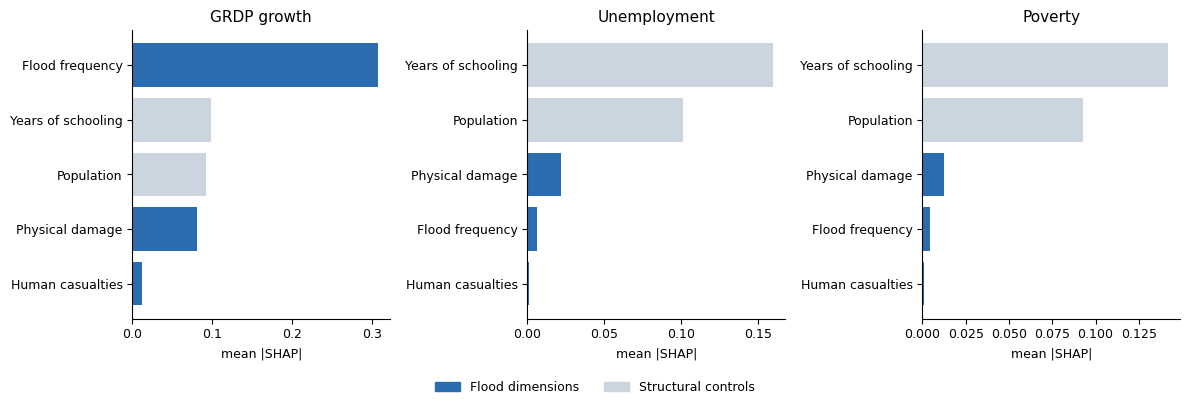

In [37]:
# ═══════════════════════════════════════════════════════════════════════
# Combine the three per-outcome mean|SHAP| CSVs into ONE 3-panel bar figure
# for the main text. Run after the three notebooks have each exported their
# CSV via shap_export_per_notebook.py.
#
# Message the figure carries (must be reinforced by the caption):
#   - For poverty and unemployment, structural controls (population,
#     schooling) dominate mean|SHAP|; flood dimensions are minor.
#   - For growth, flood dimensions rank higher, BUT the model has no
#     out-of-sample skill (see main-text R2), so the ranking is among
#     uniformly weak predictors.
#   => importance ranking is NOT evidence of useful prediction.
# ═══════════════════════════════════════════════════════════════════════
import pandas as pd
import matplotlib.pyplot as plt

outcomes = [("grdp_growth_pct", "GRDP growth"),
            ("tpt_pct", "Unemployment"),
            ("poverty_pct", "Poverty")]

# optional: nicer feature labels
LABELS = {
    "event_count_log": "Flood frequency",
    "HCI_log": "Human casualties",
    "PDI_log": "Physical damage",
    "log_population": "Population",
    "rls_years": "Years of schooling",
}
c_flood, c_control = "#2b6cb0", "#cbd5e0"

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharex=False)

for ax, (key, title) in zip(axes, outcomes):
    df = pd.read_csv(f"../data/processed/shap_meanabs_{key}.csv")
    df = df.sort_values("mean_abs_shap", ascending=True)   # horizontal bars
    colors = [c_flood if g == "flood" else c_control for g in df["group"]]
    labels = [LABELS.get(f, f) for f in df["feature"]]
    ax.barh(labels, df["mean_abs_shap"], color=colors)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("mean |SHAP|", fontsize=9)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(labelsize=9)

# shared legend
from matplotlib.patches import Patch
handles = [Patch(color=c_flood, label="Flood dimensions"),
           Patch(color=c_control, label="Structural controls")]
fig.legend(handles=handles, loc="lower center", ncol=2, fontsize=9,
           frameon=False, bbox_to_anchor=(0.5, -0.08))

plt.tight_layout()
plt.savefig("../figures/fig_shap_bar_3panel.png", dpi=200, bbox_inches="tight")
print("Saved ../figures/fig_shap_bar_3panel.png")

In [43]:
# ═══════════════════════════════════════════════════════════════════════
# SNIPPET TO ADD IN 11_xgboost_shap_tpt.ipynb
# Saves the beeswarm plot as its own standalone PNG, so a separate script
# can stitch the three together into one 3-panel appendix figure.
# ═══════════════════════════════════════════════════════════════════════
import matplotlib.pyplot as plt
import shap

OUTCOME = "tpt_pct"

plt.figure()
shap.summary_plot(sv, Xte, feature_names=X_COLS, show=False)
plt.title("Unemployment", fontsize=11)
plt.tight_layout()
plt.savefig(f"../figures/shap_beeswarm_{OUTCOME}.png", dpi=200, bbox_inches="tight")
plt.close()
print(f"Saved ../figures/shap_beeswarm_{OUTCOME}.png")

Saved ../figures/shap_beeswarm_tpt_pct.png


In [45]:
# ═══════════════════════════════════════════════════════════════════════
# Combine the three individually-saved beeswarm PNGs into ONE 3-panel
# figure for the appendix. Run after all three notebooks (growth, poverty,
# tpt) have each saved their own shap_beeswarm_{outcome}.png via
# shap_beeswarm_export_per_notebook.py.
#
# Uses image stitching (PIL), not matplotlib subplots, because
# shap.summary_plot() builds its own internal figure and does not reliably
# accept an external `ax` argument across shap versions -- stitching
# finished images sidesteps that entirely.
# ═══════════════════════════════════════════════════════════════════════
from PIL import Image
from pathlib import Path

FIG_DIR = Path("../figures")

outcomes = ["grdp_growth_pct", "tpt_pct", "poverty_pct"]  # left-to-right order
paths = [FIG_DIR / f"shap_beeswarm_{o}.png" for o in outcomes]

for p in paths:
    assert p.exists(), f"Missing {p} -- run the export snippet in that notebook first."

images = [Image.open(p) for p in paths]

# Normalise heights (summary_plot's auto-sizing can differ slightly per
# notebook depending on number of features / label lengths), so panels
# line up cleanly when placed side by side.
target_height = min(im.height for im in images)
resized = []
for im in images:
    scale = target_height / im.height
    new_w = int(im.width * scale)
    resized.append(im.resize((new_w, target_height), Image.LANCZOS))

# Stitch horizontally with a small gap between panels
gap = 20
total_width = sum(im.width for im in resized) + gap * (len(resized) - 1)
combined = Image.new("RGB", (total_width, target_height), color="white")

x_offset = 0
for im in resized:
    combined.paste(im, (x_offset, 0))
    x_offset += im.width + gap

out_path = FIG_DIR / "fig_app_shap_beeswarm.png"
combined.save(out_path, dpi=(200, 200))
print(f"Saved {out_path}  ({combined.width}x{combined.height}px)")

Saved ..\figures\fig_app_shap_beeswarm.png  (4606x675px)
